# SOI directional coupler: Tidy3D comparison

Replicates Tidy3D's [directional coupler](https://www.flexcompute.com/tidy3d/examples/notebooks/DirectionalCoupler/) example. Silicon arms (n = 3.48, 0.22 µm thick, 30° sidewalls) on oxide (n = 1.45), air above. Layout from Tidy3D's `coupler.gds`, dilated by 20 nm per side. Light enters port 1 (lower left). We find the wavelength where power splits evenly between ports 3 and 4. Tidy3D reports 1.53 µm with total transmission 0.990 at equivalent nres=15.

## Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

# Tidy3D's coupler.gds: 0.45 um arms, 0.1 um gap, 4 um coupling length
gds_file = "coupler.gds"
dilation = 0.02  # per side, at waveguide bottom
sidewall_angle = 30  # deg from vertical
h_wg = 0.22

# domain, port positions [um]
lx, ly = 17, 7
x_port = 8
y_port = 2
source_offset = 1

# 21 frequencies over 1.4 - 1.7 um
wavelengths = np.sort(1 / np.linspace(1 / 1.7, 1 / 1.4, 21)).tolist()
wavelength = 2 / (1 / 1.4 + 1 / 1.7)


def setup(path,  sidewall_angle=sidewall_angle):
    nres=10
    shutoff = 1e-3
    tmax = 1000  # max time [periods]
    PML_decay = [0.001, 0.01, 0.1]
    shot_every = 10
    boundaries = ["PML", "PML", "PML"]
    zmin, zmax = -1.11, 1.11
    views = [lumi.view("Hz", z=h_wg / 2)]

    materials = {
        "Si": lumi.material(3.48),
        "SiO2": lumi.material(1.45),
        "air": lumi.material(1),
    }
    background = "air"

    WG = 1, 0
    BOX = 2, 0
    layer_stack = LayerStack(
        layers={
            "core": LayerLevel(
                layer=LogicalLayer(layer=WG),
                thickness=h_wg,
                zmin=0,
                material="Si",
                mesh_order=0,
                sidewall_angle=sidewall_angle,
            ),
            "box": LayerLevel(
                layer=LogicalLayer(layer=BOX),
                thickness=-zmin,
                zmin=zmin,
                material="SiO2",
                mesh_order=1,
            ),
        }
    )

    # import arms, dilate, crop to domain (extended left to fit source)
    gds = gf.import_gds(gds_file)
    dbu = gds.kcl.dbu
    arms = gf.kdb.Region(gds.begin_shapes_rec(gds.kcl.layer(1, 0)))
    arms = arms.sized(round(dilation / dbu))
    xmin = -max(lx / 2, x_port + source_offset)
    window = gf.kdb.Region(gf.kdb.Box(round(xmin / dbu), round(-ly / 2 / dbu), round(lx / 2 / dbu), round(ly / 2 / dbu)))
    c = gf.Component()
    c.add_polygon(arms & window, layer=WG)
    c.add_polygon(window, layer=BOX)

    # o1: input (lower left), o2: upper left, o3: upper right, o4: lower right
    w_wg = 0.45 + 2 * dilation
    for name, x, y, a in [
        ("o1", -x_port, -y_port, 180),
        ("o2", -x_port, y_port, 180),
        ("o3", x_port, y_port, 0),
        ("o4", x_port, -y_port, 0),
    ]:
        c.add_port(name, center=(x, y), width=w_wg, orientation=a, layer=WG)
    c.plot()

    bbox = c.bbox_np().tolist()
    bbox[0].append(zmin)
    bbox[1].append(zmax)

    frames = [
        lumi.plane_frame(
            "wg",
            start=[-1, -0.5],
            stop=[1, zmax],
            wls_mode_solver=[1.4, wavelength, 1.7],
        )
    ]
    sources = [
        lumi.gf_source(
            "o1", c, layer_stack, source_offset,
            frame="wg",
            wl=wavelength,
            bandwidth=wavelength / 8,
        )
    ]
    monitors = [lumi.gf_monitor(p, c, layer_stack, frame="wg") for p in ["o1", "o2", "o3", "o4"]]

    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)
    lumi.setup(
        path=path,
        wl=wavelength,
        wls=wavelengths,
        materials=materials,
        background=background,
        boundaries=boundaries,
        bbox=bbox,
        frames=frames,
        sources=sources,
        monitors=monitors,
        nres=nres,
        tmax=tmax,
        shutoff=shutoff,
        PML_decay=PML_decay,
        views=views,
        shot_every=shot_every,
    )
    return c


## Simulate

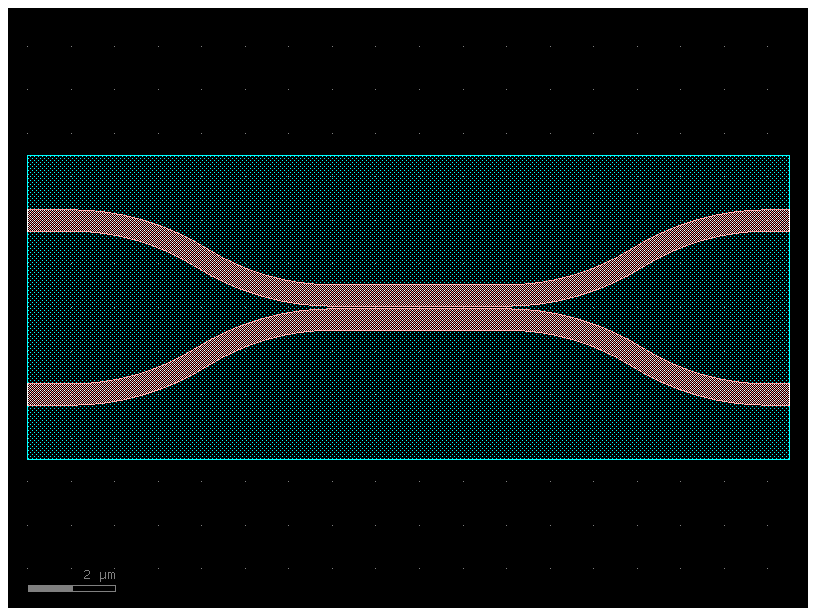

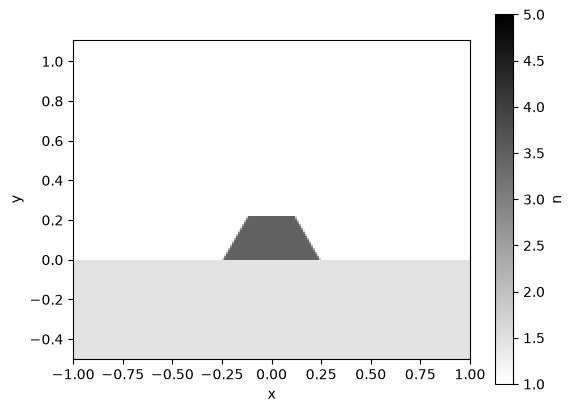

using simulation folder runs/SOI_coupler


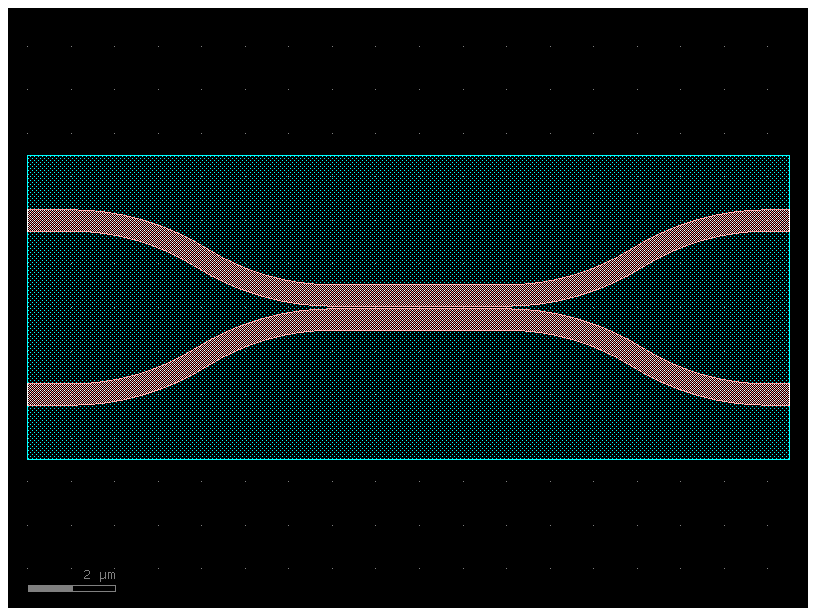

In [2]:
path = os.path.join("runs", "SOI_coupler")
setup(path)

backend using simulation folder runs/SOI_coupler


setting up simulation...


processing geometry bodies...


generating voxels...


voxelation: 2.844243 seconds (29.89 M allocations: 1.034 GiB, 3.24% gc time, 276.92% compilation time)


Yee mode λ=0.9118: neff 2.2273


... (11 outputs left out)

period 50, decay: 0.95, 0.065 seconds/period, 12210.19 Mcells/s


period 60.0, decay: 0.307, 0.065 seconds/period, 12153.99 Mcells/s


period 65.25 stop on energy decay
12131.62 Mcells/s


simulation completed.


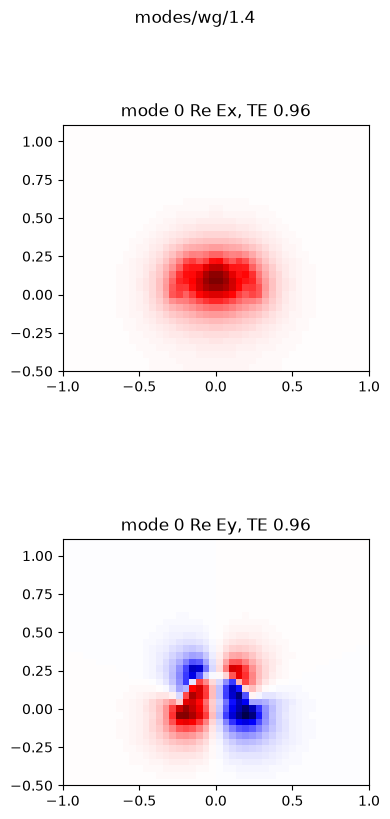

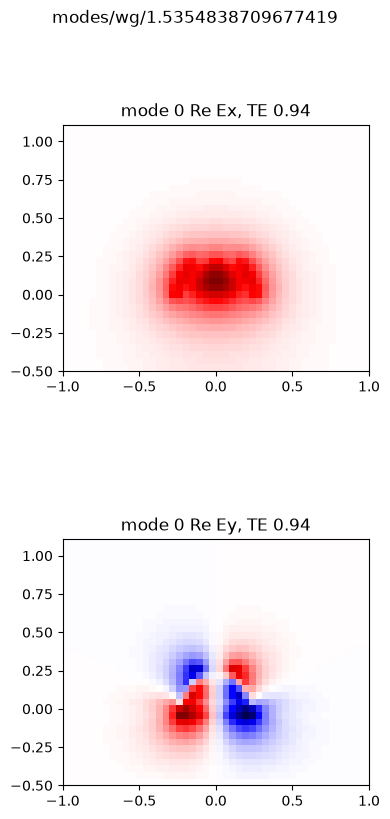

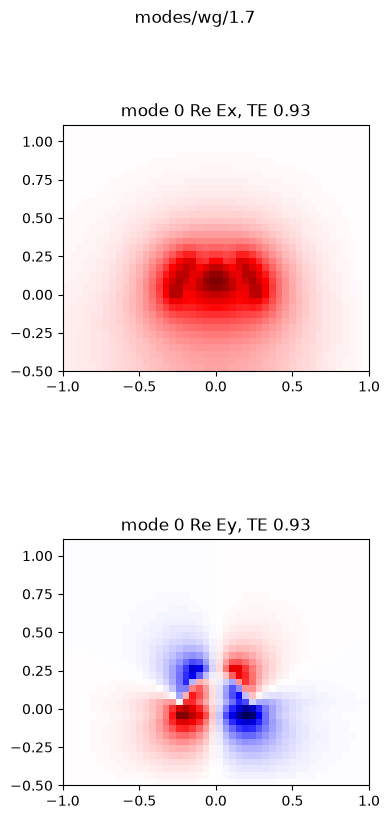

In [3]:
lumi.solve(path)

## Results

loading solution from runs/SOI_coupler
may take a minute if simulation folder is remotely mounted
50/50 at 1.531 um, total transmission 0.993


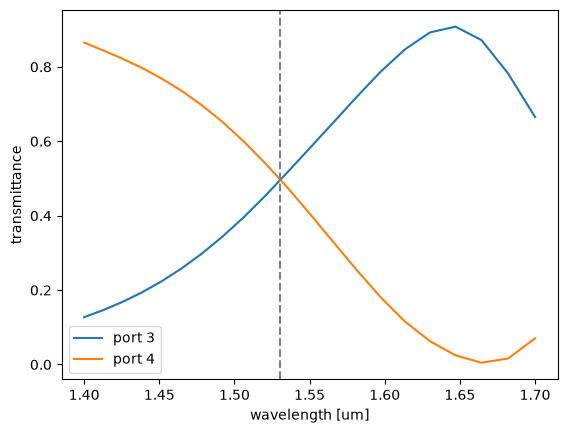

In [4]:
sol = lumi.load(path)
m = sol["monitors"]
a1 = m["o1"]["modes"][0]["-"]
T3 = np.abs(m["o3"]["modes"][0]["+"] / a1) ** 2
T4 = np.abs(m["o4"]["modes"][0]["+"] / a1) ** 2
wls = np.array(wavelengths)

# 50/50 crossing
diff = T3 - T4
i = np.where(np.diff(np.sign(diff)))[0][0]
t = diff[i] / (diff[i] - diff[i + 1])
wl_cross = wls[i] + t * (wls[i + 1] - wls[i])
T_cross = (T3[i] + T4[i]) * (1 - t) + (T3[i + 1] + T4[i + 1]) * t
print(f"50/50 at {wl_cross:.3f} um, total transmission {T_cross:.3f}")

plt.plot(wls, T3, label="port 3")
plt.plot(wls, T4, label="port 4")
plt.axvline(wl_cross, color="gray", ls="--")
plt.xlabel("wavelength [um]")
plt.ylabel("transmittance")
plt.legend()
plt.show()

## Movie

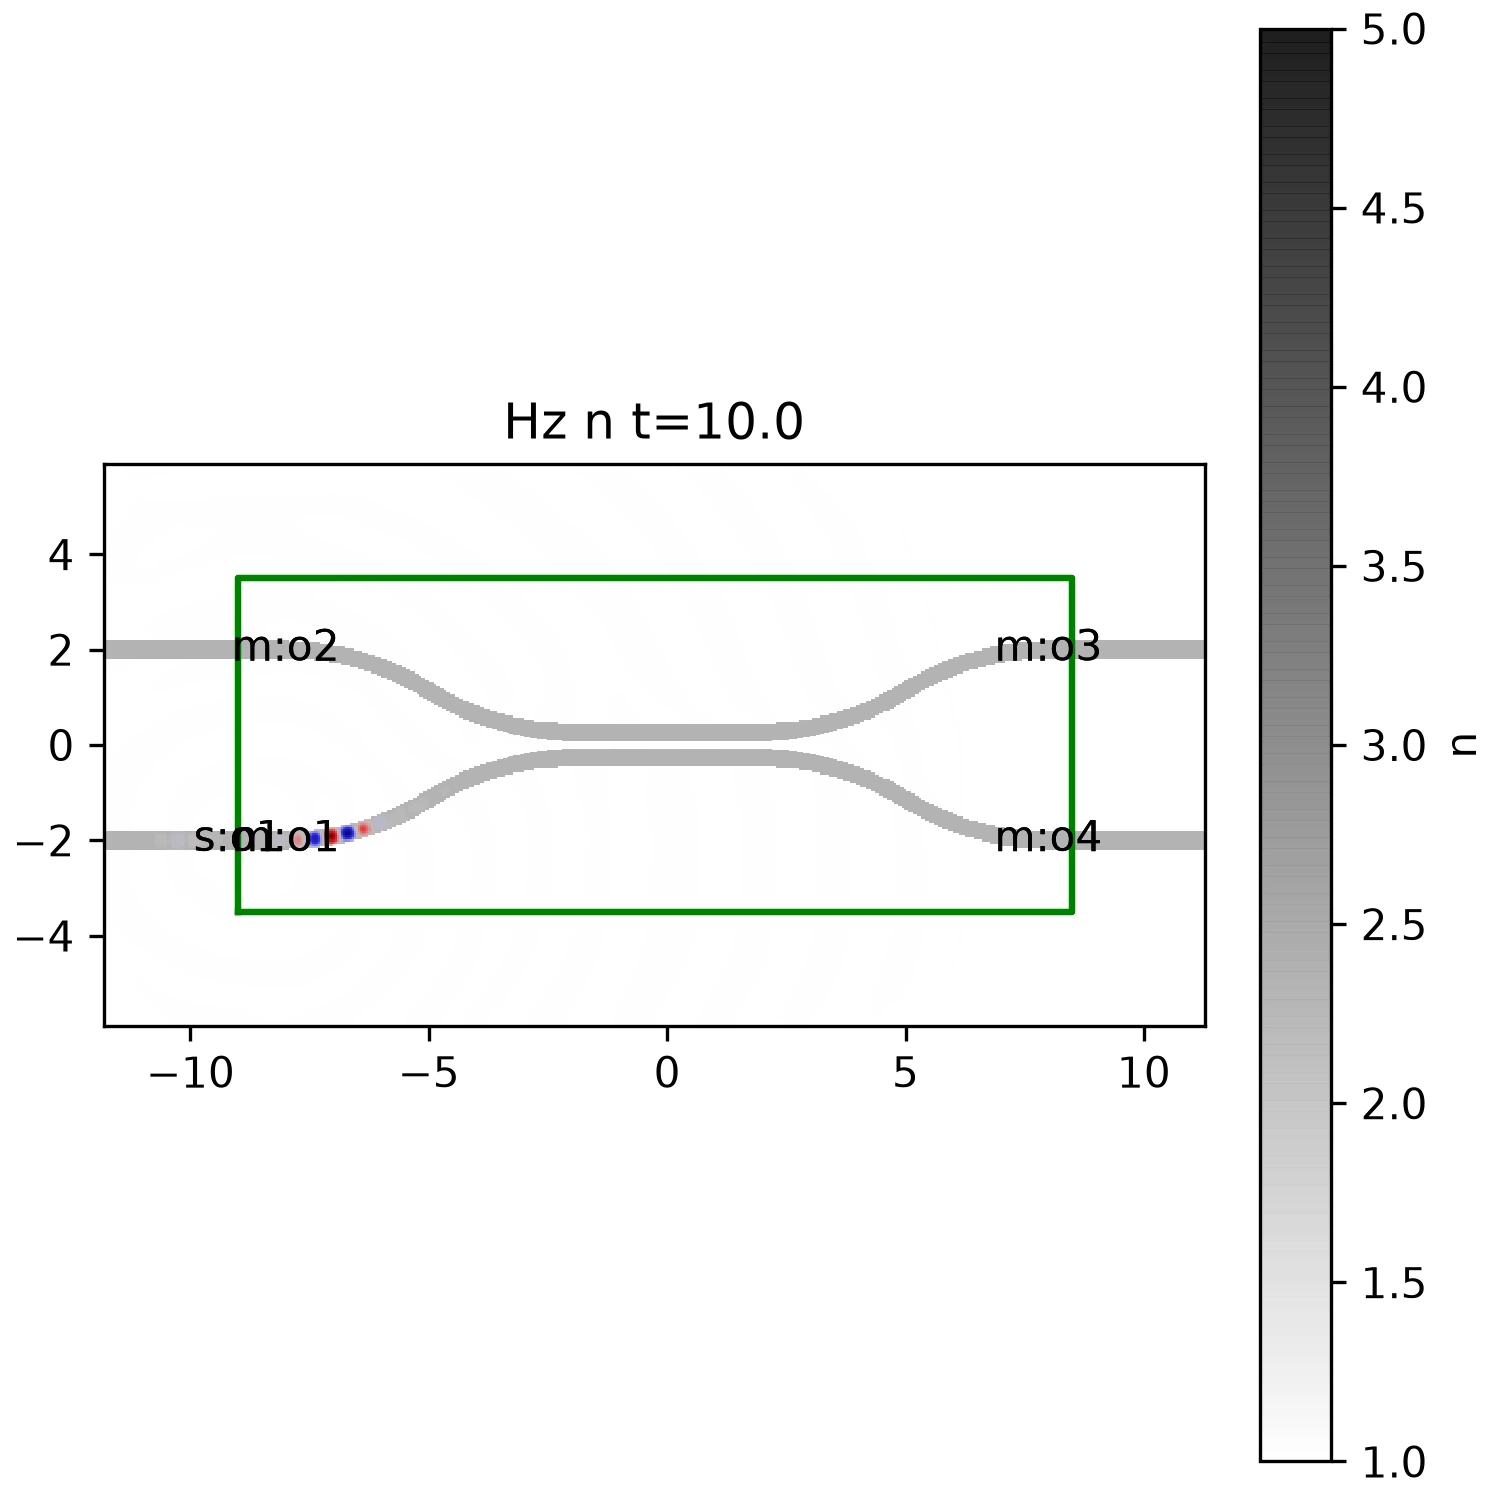

In [5]:
lumi.movie(path)